# ۰۷ - بررسی عملکرد ارسال سفارش‌ها

پاسخ به سؤال‌های بخش ۹ صورت‌مسئله: زمان تحویل، تأخیر، تفکیک جغرافیایی و روند زمانی.

## ۲. سؤال‌های کسب‌وکاری

1. مدت زمان ثبت تا تحویل چقدر است و توزیع آن چگونه است؟
2. چند درصد سفارش‌ها دیرکرددار هستند؟
3. میانگین تأخیر در سفارش‌های دیرکرددار چقدر است؟
4. کدام ایالت‌ها کندتر هستند؟
5. روند زمان تحویل و نرخ تأخیر در طول زمان چگونه است؟

## ۱. عنوان و هدف

پاسخ به سؤال‌های بخش ۹ صورت‌مسئله: زمان تحویل، تأخیر، تفکیک جغرافیایی و روند زمانی.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from olist_analysis import metrics as M
from olist_analysis.config import FIGURES_DIR, REPORTS_DIR, TABLES_DIR
from olist_analysis.font_utils import persian_available
from olist_analysis.features import load_dataset
from olist_analysis.pipeline import load_headline

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

ds = load_dataset()
headline = load_headline()
print("Persian font registered for charts:", persian_available())
print(f"orders={len(ds.orders):,}  items={len(ds.items):,}  "
      f"delivered={len(ds.delivered):,}  reviewed={len(ds.reviews_per_order):,}")


Persian font registered for charts: True
orders=99,441  items=112,650  delivered=96,470  reviewed=98,673


## ۴. روش محاسبه

- مدت تحویل = تاریخ تحویل واقعی منهای تاریخ ثبت سفارش (بر حسب روز).
- تأخیر = تاریخ تحویل واقعی منهای تاریخ تخمینی تحویل، بر پایه **تاریخ تقویمی**.
- سفارش زودتر از موعد: تأخیر کمتر از صفر؛ به‌موقع: مساوی صفر؛ دیرکرددار: بیشتر از صفر.
- همه شاخص‌ها فقط روی ۹۶٬۴۷۰ سفارش تحویل‌شده دارای تاریخ محاسبه می‌شوند.

## ۶. تحلیل عددی

### ۹.۱ و ۹.۲ آمار زمان تحویل

In [2]:
display(M.delivery_duration_summary(ds))

,n_delivered_orders,n_missing_duration,mean_days,median_days,min_days,max_days,std_days,p25_days,p75_days,p90_days,p99_days,mean_promised_days,median_promised_days,mean_days_earlier_than_promise
0,96470,2971,12.5582,10.2175,0.5334,209.6286,9.5462,6.7662,15.7202,23.0964,46.0503,23.7363,23.2309,11.1781


In [3]:
display(pd.Series(M.delivery_distribution_stats(ds), name="value"))

n                         96470.0000
q1_days                       6.7662
q3_days                      15.7202
iqr_days                      8.9540
upper_fence_days             29.1512
n_outliers                 4896.0000
pct_outliers                  5.0752
pct_within_7_days            26.9991
pct_within_15_days           72.6578
pct_within_30_days           95.2835
pct_over_30_days              4.7165
skewness                      3.8334
mean_minus_median_days        2.3407
Name: value, dtype: float64

### ۹.۴ تا ۹.۶ طبقه‌بندی تأخیر

In [4]:
display(M.delivery_class_summary(ds))

,delivery_class,n_orders,pct_of_delivered,definition,avg_delay_days
0,early,88644,91.8876,delivered before the promised date,-13.71
1,on_time,1292,1.3393,delivered on the promised date,0.0
2,late,6534,6.7731,delivered after the promised date,10.62


In [5]:
display(M.delay_summary(ds))

,metric,value
0,delivered orders analysed,96470.0000
1,late orders,6534.0000
2,late share of delivered (%),6.7731
3,late orders > 7 days,2862.0000
4,late orders 4-7 days,1802.0000
5,late orders 1-3 days,1870.0000
6,late orders > 15 days,1225.0000
7,mean delay days (late only),10.6201
8,median delay days (late only),7.0000
9,p90 delay days (late only),22.0000


### ۹.۷ و ۹.۸ عملکرد تحویل به تفکیک ایالت

In [6]:
display(M.delivery_by_state(ds))

,customer_state,n_orders,mean_delivery_days,median_delivery_days,mean_promised_days,n_late,mean_early_days,pct_late,meets_min_sample,rank_slowest
0,RR,41,29.39,25.01,45.98,5,-17.29,12.1951,False,1
1,AP,67,27.19,24.35,46.24,2,-19.69,2.9851,False,2
2,AM,145,26.43,25.88,45.28,4,-19.57,2.7586,True,3
3,AL,397,24.54,22.33,32.58,85,-8.71,21.4106,True,4
4,PA,946,23.77,21.08,37.16,106,-14.07,11.2051,True,5
5,MA,717,21.57,19.19,30.46,125,-9.57,17.4338,True,6
6,SE,335,21.52,18.01,30.85,51,-10.02,15.2239,True,7
7,CE,1279,21.27,18.21,31.38,176,-10.8,13.7608,True,8
8,AC,80,21.04,18.36,41.11,3,-20.72,3.7500,False,9
9,PB,517,20.43,18.15,33.03,54,-13.26,10.4449,True,10


### ۹.۹ و ۹.۱۰ روند زمانی

In [7]:
display(M.monthly_delivery_trend(ds))

,purchase_ym,n_orders,mean_delivery_days,median_delivery_days,n_late,in_core_window,pct_late,order_month
0,2016-09,1,54.81,54.81,1,False,100.0000,2016-09-01
1,2016-10,265,19.60,17.94,2,False,0.7547,2016-10-01
2,2016-12,1,4.69,4.69,0,False,0.0000,2016-12-01
3,2017-01,750,12.65,10.73,22,True,2.9333,2017-01-01
4,2017-02,1653,13.17,10.97,49,True,2.9643,2017-02-01
5,2017-03,2546,12.95,10.13,116,True,4.5562,2017-03-01
6,2017-04,2303,14.92,12.75,151,True,6.5567,2017-04-01
7,2017-05,3545,11.32,9.79,106,True,2.9901,2017-05-01
8,2017-06,3135,12.01,10.80,95,True,3.0303,2017-06-01
9,2017-07,3872,11.59,10.16,108,True,2.7893,2017-07-01


## ۷. نمودارها

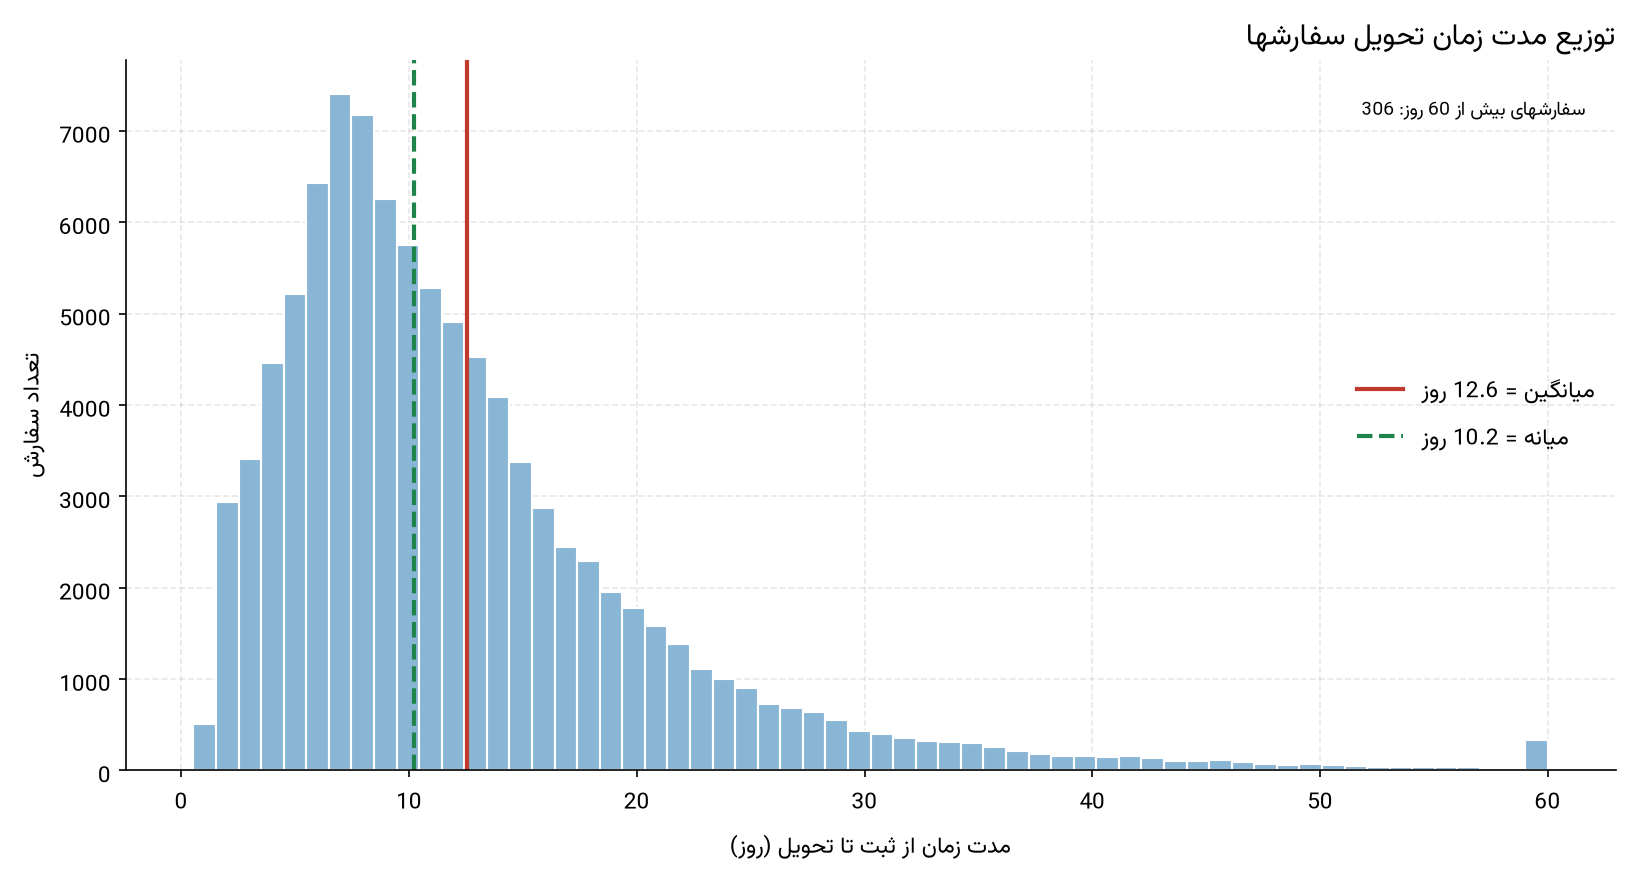

نمودار ۱۵ - توزیع چوله به راست؛ میانگین بالاتر از میانه است


In [8]:
display(Image(filename=str(FIGURES_DIR / "fig_15_delivery_histogram.png"), width=920))
caption = FIGURES_DIR / "fig_15_delivery_histogram.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

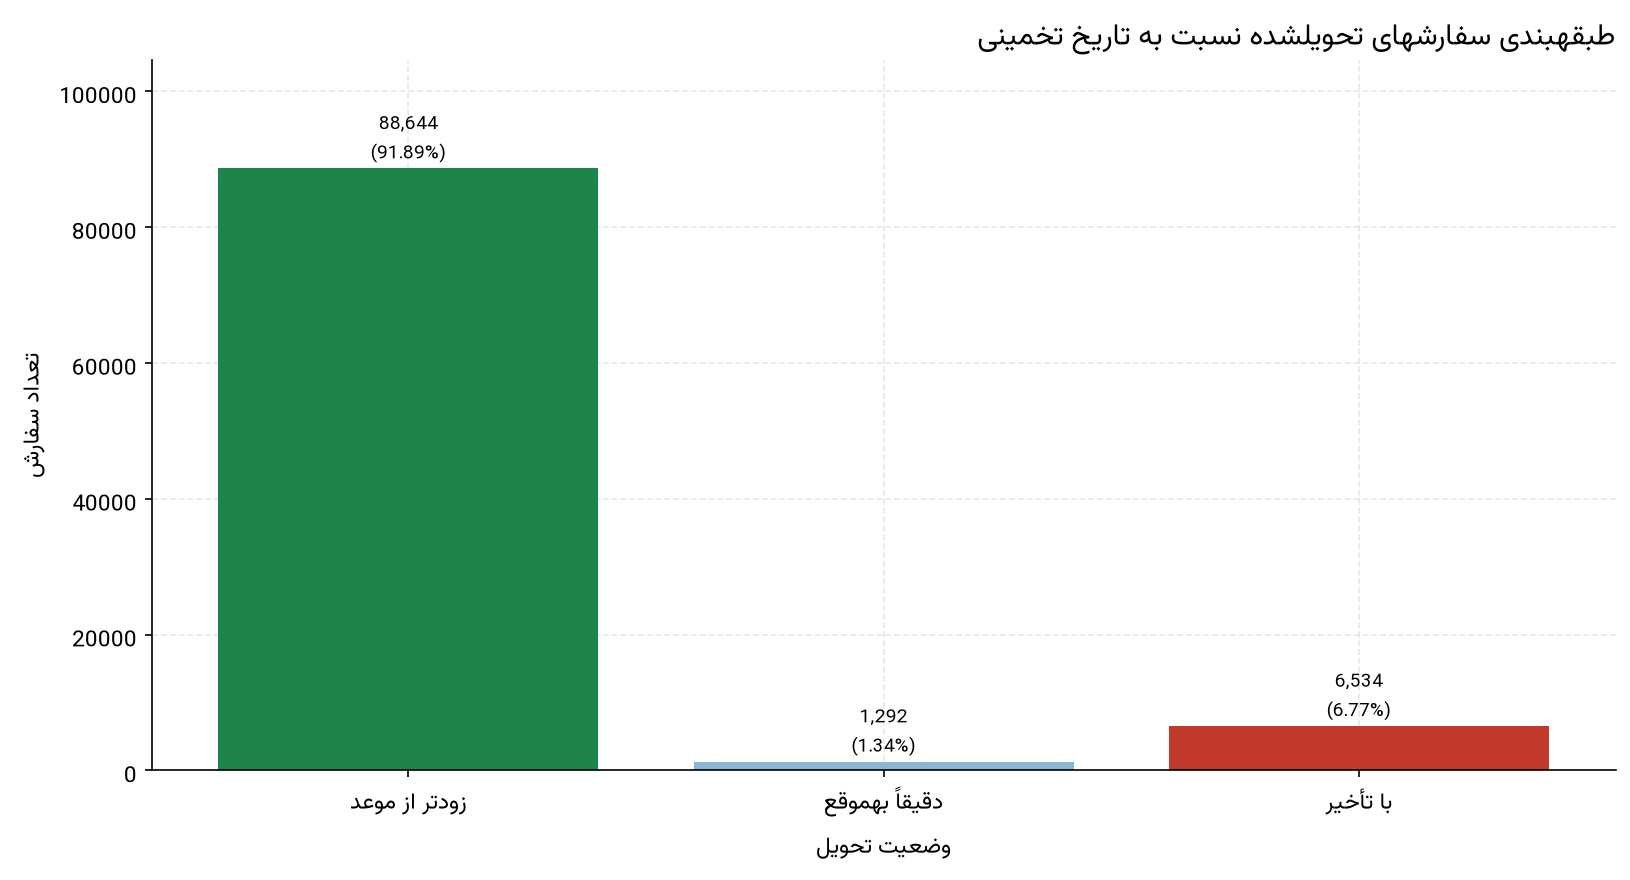

نمودار ۱۶ - تفکیک سفارشهای تحویلشده به زودتر از موعد، بهموقع و دیرکرددار


In [9]:
display(Image(filename=str(FIGURES_DIR / "fig_16_delivery_class.png"), width=920))
caption = FIGURES_DIR / "fig_16_delivery_class.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

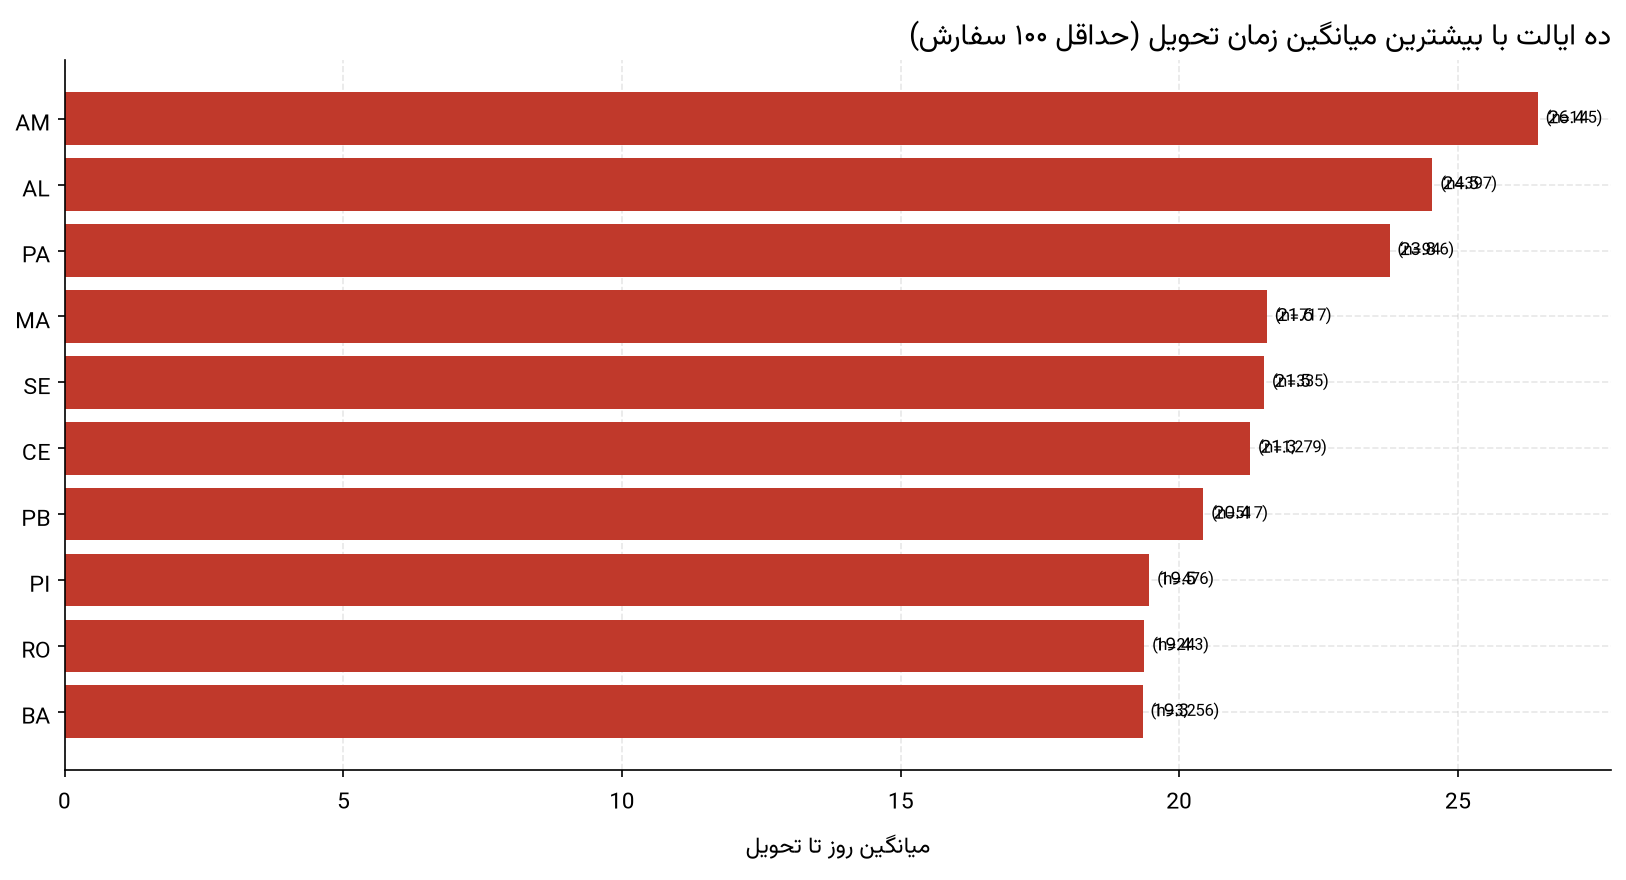

نمودار ۱۷ - میانگین زمان تحویل در ایالتها همراه با حجم نمونه


In [10]:
display(Image(filename=str(FIGURES_DIR / "fig_17_state_delivery.png"), width=920))
caption = FIGURES_DIR / "fig_17_state_delivery.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

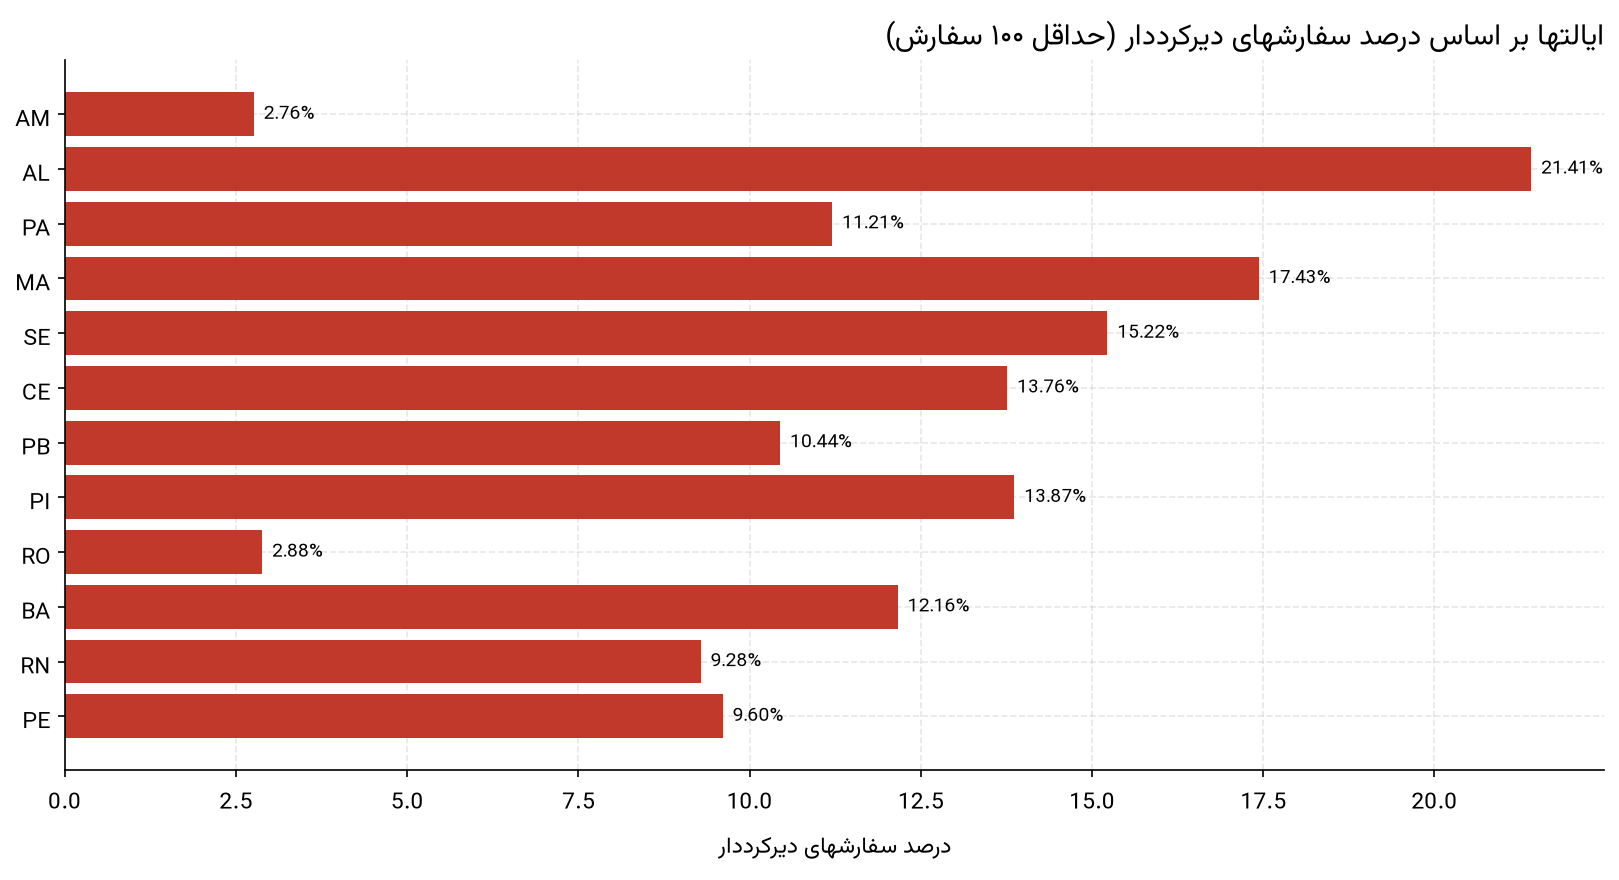

نمودار ۳۱ - نرخ تأخیر در ایالتها همراه با حجم نمونه


In [11]:
display(Image(filename=str(FIGURES_DIR / "fig_31_state_late_rate.png"), width=920))
caption = FIGURES_DIR / "fig_31_state_late_rate.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

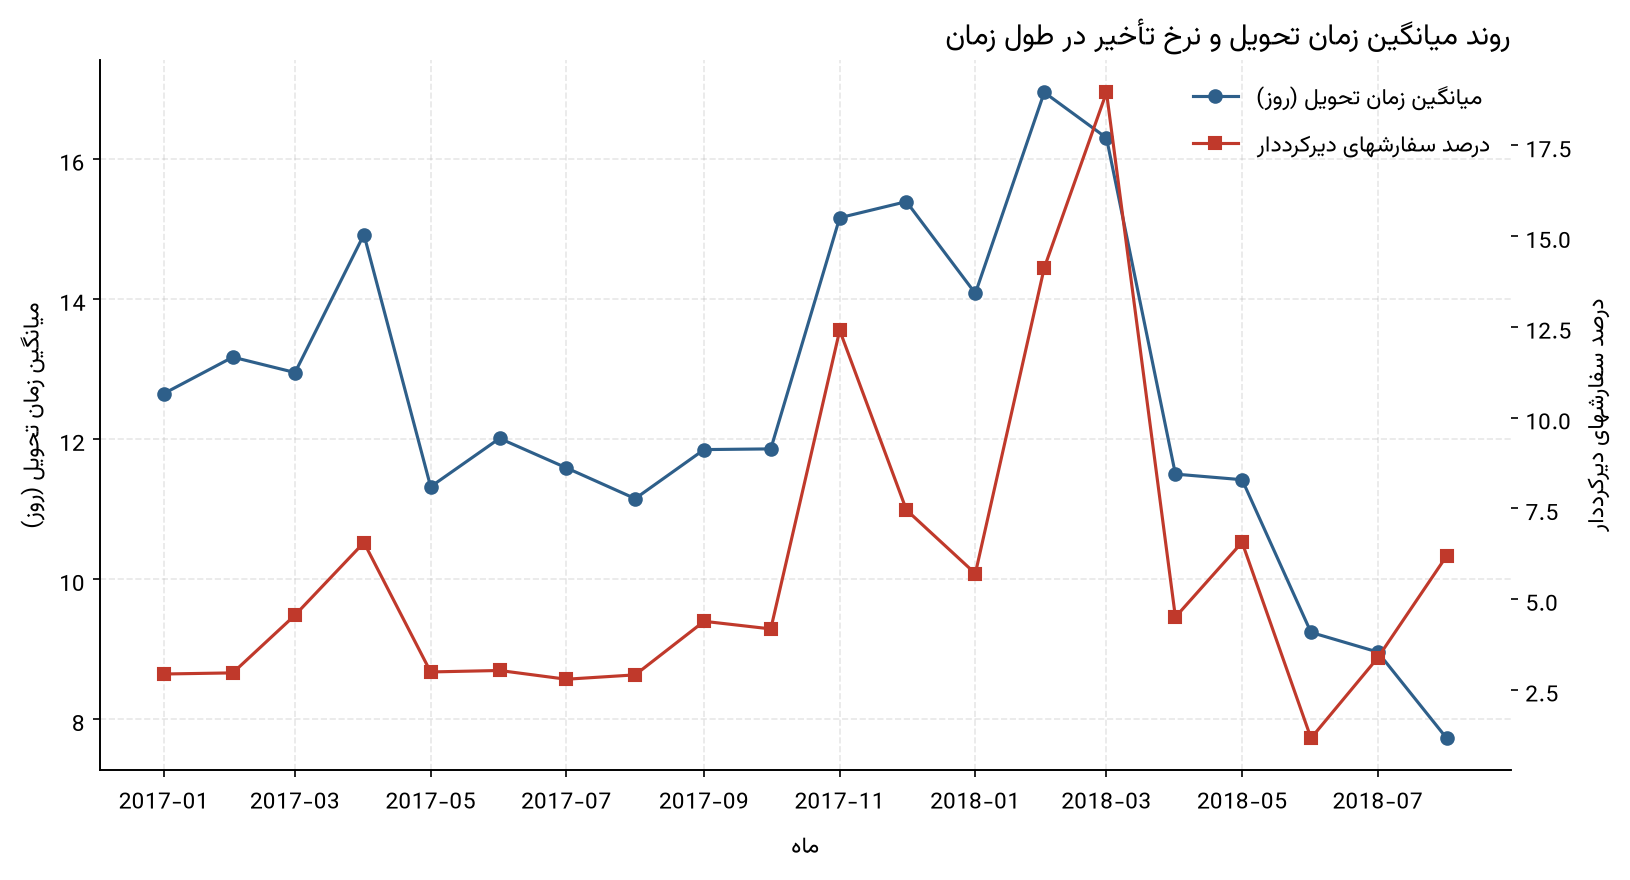

نمودار ۱۸ - روند زمانی زمان تحویل و نرخ تأخیر در پنجره تحلیلی


In [12]:
display(Image(filename=str(FIGURES_DIR / "fig_18_monthly_delivery_trend.png"), width=920))
caption = FIGURES_DIR / "fig_18_monthly_delivery_trend.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

## ۸. یافته‌های واقعی

- میانگین زمان تحویل ۱۲.۵۶ روز و میانه آن ۱۰.۲۲ روز است؛ فاصله ۲.۳۴ روزه میان آن دو نشان می‌دهد توزیع چوله به راست است.
- ۴٬۸۹۶ سفارش (۵.۰۸ درصد) از سقف آماری فاصله میان‌چارکی بالاتر هستند و بیشترین زمان تحویل ۲۰۹.۶۳ روز است.
- ۹۱.۸۹ درصد سفارش‌ها زودتر از وعده، ۱.۳۴ درصد دقیقاً سر وعده و ۶.۷۷ درصد (۶٬۵۳۴ سفارش) با تأخیر تحویل شده‌اند.
- میانگین تأخیر در سفارش‌های دیرکرددار ۱۰.۶۲ روز و میانه آن ۷ روز است؛ ۲٬۸۶۲ سفارش بیش از ۷ روز تأخیر دارند.
- میانگین زمان تحویل از ۸.۷۶ روز در SP تا ۲۹.۳۹ روز در RR تغییر می‌کند.
- ایالت‌های AL، MA، CE، SE، PA، PB، PI و BA هم‌زمان کند و پرتأخیر هستند؛ AL با ۲۱.۴۱ درصد نرخ تأخیر بدترین وضعیت را دارد.

## ۹. تفسیر کسب‌وکاری

تأخیر یک مشکل سراسری نیست: ۹۱.۹ درصد سفارش‌ها زودتر از وعده می‌رسند. نرخ تأخیر در ایالت‌های شمال و شمال‌شرق چند برابر جنوب و جنوب‌شرق است، پس اقدام اصلاحی می‌تواند هدفمند و کم‌هزینه باشد. همچنین وعده‌های اعلامی برای این مناطق حاشیه امن بزرگی دارند (میانگین ۳۲.۵۸ روز وعده در برابر ۲۴.۵۴ روز تحویل واقعی در AL).

## ۱۰. محدودیت‌های تحلیل

۸ سفارش تحویل‌شده تاریخ تحویل واقعی ندارند و از محاسبات کنار گذاشته شده‌اند. ۱٬۳۵۹ سفارش ترتیب زمانی غیرمنتظره بین تأیید و تحویل به شرکت حمل دارند که ثبت دیرهنگام است و بر شاخص‌های اصلی اثر ندارد.

## ۱۱. نتیجه‌گیری

عملکرد ارسال در مجموع قابل قبول است، اما بخش کوچکی از سفارش‌ها با تأخیر طولانی تحویل می‌شوند و این تأخیر در چند ایالت مشخص متمرکز است؛ همین نقاط باید هدف اقدام عملیاتی باشند.